# Projet : simulation de la Ligue des champions

Dans ce projet, on a voulu savoir quelles sont les chances de chaque club de gagner la Ligue des champions (ou d'aller en huitièmes, en quarts, etc.).

Pour ça, on simule toute la compétition (phase de ligue + phase finale) 10 000 fois sur ordinateur, avec des scores tirés au hasard. Ensuite on compte : si un club gagne dans 2 000 simulations sur 10 000, on dit qu'il a 20 % de chances de gagner. C'est la méthode de Monte-Carlo.

### Comment lancer le notebook

1. Installer le kernel Julia (une seule fois) : `using Pkg; Pkg.add("IJulia")`
2. Ouvrir le notebook avec le kernel Julia
3. Faire **Run All**

Pas besoin d'avoir notre dossier : la première cellule télécharge le projet depuis GitHub. La première fois c'est un peu long (une dizaine de minutes), après ça prend environ 3 minutes.

Les résultats sont déjà dans le notebook, donc on peut aussi juste le lire.

## 1. On charge le projet

In [1]:
using Pkg
Pkg.activate(temp = true) # environnement temporaire
Pkg.add(url = "https://github.com/Akashii-touc/SimulationsProjet.jl", rev = "dev")
Pkg.add(["DataFrames", "GLMakie"])

using SimulationsProjet, DataFrames, GLMakie
GLMakie.activate!(inline = true) # graphiques dans le notebook

N = 10000 # nombre de simulations

  Activating new project at `C:\Users\yaya\AppData\Local\Temp\jl_MYhEol`
    Updating git-repo `https://github.com/Akashii-touc/SimulationsProjet.jl`

   Resolving package versions...


    Updating `C:\Users\yaya\AppData\Local\Temp\jl_MYhEol\Project.toml`
  [1c7c81b7] + SimulationsProjet v0.0.1 `https://github.com/Akashii-touc/SimulationsProjet.jl#dev`
    Updating `C:\Users\yaya\AppData\Local\Temp\jl_MYhEol\Manifest.toml`
 

 [621f4979] + AbstractFFTs v1.5.0
  [1520ce14] + AbstractTrees v0.4.5
  [7d9f7c33] + Accessors v0.1.46
  [79e6a3ab] + Adapt v4.7.4
  [4f381ef7] + AdaptiveArrayPools v0.3.12
  [35492f91] + AdaptivePredicates v1.2.0
  [66dad0bd] + AliasTables v1.1.3
  [27a7e980] + Animations v0.4.2
  [67c07d97] + Automa v1.2.0
  [13072b0f] + AxisAlgorithms v1.1.0
  [39de3d68] + AxisArrays v0.4.8
  [18cc8868] + BaseDirs v1.4.0
⌅ [fa961155] + CEnum v0.5.0
  [96374032] + CRlibm v1.1.0
  [336ed68f] + CSV v1.2.0
  [d360d2e6] + ChainRulesCore v1.26.7
  [da1fd8a2] + CodeTracking v3.0.2
  [944b1d66] + CodecZlib v0.7.9
  [6b39b394] + CodecZstd v0.8.7
  [a2cac450] + ColorBrewer v0.4.2
  [35d6a980] + ColorSchemes v3.31.0
  [3da002f7] + ColorTypes v0.12.5
  [c3611d14] + ColorVectorSpace v0.11.2
  [5ae59095] + Colors v0.13.4
  [38540f10] + CommonSolve v0.2.14
  [34da2185] + Compat v4.18.1
  [807dbc54] + Compiler v0.1.1
  [a33af91c] + CompositionsBase v0.1.2
  [95dc2771] + ComputePipeline v0.1.8
  [187b0558] + Constru

+ Libmount_jll v2.42.4+0
  [89763e89] + Libtiff_jll v4.7.3+0
  [38a345b3] + Libuuid_jll v2.42.4+0
  [e7412a2a] + Ogg_jll v1.3.6+0
  [6cdc7f73] + OpenBLASConsistentFPCSR_jll v0.3.34+0
  [18a262bb] + OpenEXR_jll v3.5.2+0
  [95196869] + OpenJPH_jll v0.32.0+0
  [efe28fd5] + OpenSpecFun_jll v0.5.6+0
  [91d4177d] + Opus_jll v1.6.1+0
  [36c8627f] + Pango_jll v1.58.2+0
  [30392449] + Pixman_jll v0.46.4+0
  [f50d1b31] + Rmath_jll v0.5.2+0
  [a2964d1f] + Wayland_jll v1.24.0+0
  [ffd25f8a] + XZ_jll v5.8.4+0
  [4f6342f7] + Xorg_libX11_jll v1.8.14+0
  [0c0b7dd1] + Xorg_libXau_jll v1.0.13+0
  [935fb764] + Xorg_libXcursor_jll v1.2.4+0
  [a3789734] + Xorg_libXdmcp_jll v1.1.6+0
  [1082639a] + Xorg_libXext_jll v1.3.8+0
  [d091e8ba] + Xorg_libXfixes_jll v6.0.2+0
  [a51aa0fd] + Xorg_libXi_jll v1.8.5+0
  [d1454406] + Xorg_libXinerama_jll v1.1.7+0
  [ec84b674] + Xorg_libXrandr_jll v1.5.6+0
  [ea2f1a96] + Xorg_libXrender_jll v0.9.13+0
  [a65dc6b1] + Xorg_libpciaccess_jll v0.19.0+0
  [c7cfdc94] + Xorg_libxcb_

+ nghttp2_jll v1.67.1+0
  [3f19e933] + p7zip_jll v17.8.2+0
        Info Packages marked with ⌅ have new versions available but compatibility constraints restrict them from upgrading. To see why use `status --outdated -m`


Precompiling packages...


   7.2 s  ✓ SimulationsProjet
  1 dependency successfully precompiled in 9 seconds. 333 already precompiled.
    Updating `C:\Users\yaya\AppData\Local\Temp\jl_MYhEol\Project.toml`
  [a93c6f00] + DataFrames v1.8.2
  [e9467ef8] + GLMakie v0.13.16
    Manifest

 No packages added to or removed from `C:\Users\yaya\AppData\Local\Temp\jl_MYhEol\Manifest.toml`


10000

## 2. Les données

On a récupéré trois fichiers :
- `classement_club.csv` : les coefficients UEFA des 36 clubs (celui du club et celui de son pays)
- `matchs.csv` : le calendrier des 8 journées de la phase de ligue
- `tirs_au_but.csv` : les séances de tirs au but de chaque club, avec le nombre de tirs tentés et réussis

In [2]:
first(CLASSEMENT, 10)

Row,Club,Pays,Coeff_club,Coeff_pays,Elo
,String,String,Float64,Float64,Int64
1,Bayern,Allemagne,129.5,81.545,2046
2,Arsenal,Angleterre,127.0,103.796,2040
3,RealMadrid,Espagne,122.5,83.243,1972
4,ParisSG,France,121.0,69.153,1956
5,Inter,Italie,115.0,88.589,1946
6,ManCity,Angleterre,106.5,103.796,2028
7,Barcelone,Espagne,106.25,83.243,2024
8,Liverpool,Angleterre,105.0,103.796,1937
9,Dortmund,Allemagne,98.75,81.545,1900


In [3]:
first(CALENDRIER, 5)

Row,Match_1,Match_2,Match_3,Match 4,Match_5,Match_6,Match_7,Match_8
,String,String,String,String,String,String,String,String
1,Brugge - AstonVilla,Lens - Sporting,Fenerbahçe - SlaviaPrague,Shakhtar - Sporting,Bodo/Glimt - LASK,Villarreal - SabahFC,Bodo/Glimt - AtléticoMadrid,ParisSG - Galatasaray
2,AEKAthènes - LASK,SabahFC - SlaviaPrague,SabahFC - Dortmund,Galatasaray - Stuttgart,Galatasaray - AstonVilla,Viking - Feyenoord,Galatasaray - Feyenoord,Bayern - Betis
3,RealMadrid - Inter,Inter - Brugge,ParisSG - Barcelone,Barcelone - AstonVilla,RealMadrid - PSV,Bayern - SlaviaPrague,RealMadrid - LASK,Liverpool - Lens
4,Dortmund - Villarreal,Arsenal - Lille,Liverpool - Villarreal,AtléticoMadrid - Bayern,ManCity - Naples,Barcelone - ManCity,Inter - Liverpool,ManCity - Sporting
5,Porto - ManCity,AtléticoMadrid - ManUnited,ManCity - AEKAthènes,ManUnited - Roma,Arsenal - Dortmund,Roma - Sporting,AstonVilla - Dortmund,Arsenal - SabahFC


In [4]:
first(STATS_TAB, 5)

Row,Club,seances_jouees,seances_gagnees,tirs_tentes,tirs_reussis
,String,Int64,Int64,Int64,Int64
1,Bayern,11,7,55,43
2,Arsenal,13,8,63,53
3,RealMadrid,6,5,27,22
4,ParisSG,13,8,64,52
5,Inter,6,2,31,20


### La force d'un club

Pour savoir si un club est fort, on lui donne un poids $w$ calculé à partir de ses coefficients UEFA. On compte surtout le coefficient du club (80 %) et un peu celui du pays (20 %) :

$$F = 0.8 \times \text{Coeff}_\text{club} + 0.2 \times \text{Coeff}_\text{pays}$$

Puis on ramène ça autour de 0, pour que les poids restent petits :

$$w = \frac{F - \overline{F}}{\max F - \min F}$$

### Les tirs au but

Pour chaque club, on regarde combien de tirs au but il a réussis. Mais certains clubs ont tiré très peu de fois, et ça ne suffit pas pour se faire une idée. On mélange donc avec 75 %, qui est à peu près la moyenne :

$$p = \frac{\text{réussis} + 0.75 \times 10}{\text{tentés} + 10}$$

Un club qui a tiré beaucoup de fois garde à peu près son vrai pourcentage. Un club qui a peu tiré reste proche de 75 %.

## 3. Comment on tire les scores

Pour un match entre $A$ (à domicile) et $B$, on calcule d'abord la différence de force $\Delta = w_A - w_B$, puis le nombre moyen de buts de chaque équipe :

$$\lambda_A = \mu \times 1.2 \times e^{\Delta}, \qquad \lambda_B = \mu \times e^{-\Delta}$$

- plus $A$ est fort par rapport à $B$, plus $\lambda_A$ est grand ;
- le $1.2$ donne un petit avantage à l'équipe qui joue à domicile ;
- $\mu$ règle le nombre de buts. On l'a choisi pour avoir environ 3 buts par match, comme en vrai en Ligue des champions.

On a ensuite testé 4 façons (4 modèles) de tirer les scores à partir de $\lambda_A$ et $\lambda_B$ :

| Modèle | Idée | Paramètres |
|---|---|---|
| Poisson | les buts de chaque équipe suivent une loi de Poisson, chacun de son côté | μ = 1.25 |
| Poisson bivariée | pareil, plus des buts « en commun » aux deux équipes (pour avoir plus de matchs serrés entre équipes proches) | μ = 1, λ commun = 0.4 |
| Binomiale négative | même moyenne que Poisson, mais les scores varient plus | μ = 1.25, p = 0.8 |
| Dixon-Coles | Poisson, mais corrigé sur les petits scores (0-0, 1-0, 0-1, 1-1), que Poisson ne prévoit pas assez bien | μ = 1.25, ρ = -0.1 |

Rappel, la loi de Poisson : $P(X = k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$

## 4. Comment se passe une simulation

1. **Phase de ligue :** on joue les 8 journées du calendrier. Une victoire rapporte 3 points, un nul 1 point.
2. **Classement :** les 8 premiers vont directement en huitièmes, les places 9 à 24 passent par un barrage, les 12 derniers sont éliminés.
3. **Phase finale :** matchs aller-retour. En cas d'égalité, il y a une prolongation puis des tirs au but. La finale se joue en un seul match.

## 5. Résultats (modèle de Dixon-Coles)

In [5]:
df = classement_stats(rand(N, ModeleDixonColes(); seed = 1))
show(df, allrows = true, allcols = true)

36×10 DataFrame
 Row │ Club            xPoints  Top8     Top24    Elimine  Huitieme  Quart    Demie    Finale   Vainqueur 
     │ String          Float64  Float64  Float64  Float64  Float64   Float64  Float64  Float64  Float64   
─────┼────────────────────────────────────────────────────────────────────────────────────────────────────
   1 │ Bayern            17.62    79.26    99.71     0.29     97.07    75.64    50.95    31.07      17.5
   2 │ Arsenal           17.02    73.39    99.46     0.54     96.89    76.99    54.12    36.21      22.11
   3 │ RealMadrid        16.83    71.82    99.47     0.53     95.64    70.05    44.29    25.71      13.15
   4 │ ParisSG           16.3     64.87    99.06     0.94     93.78    65.63    39.08    20.79      10.06
   5 │ Liverpool         16.3     65.12    99.09     0.91     92.58    61.03    31.47    15.22       6.76
   6 │ Inter             15.88    59.3     98.56     1.44     91.78    61.18    33.92    17.03       8.43
   7 │ ManCity           15.

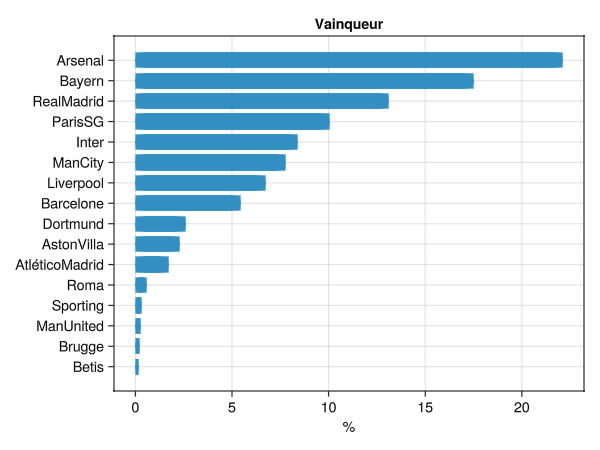

In [6]:
graphique_chances(df)

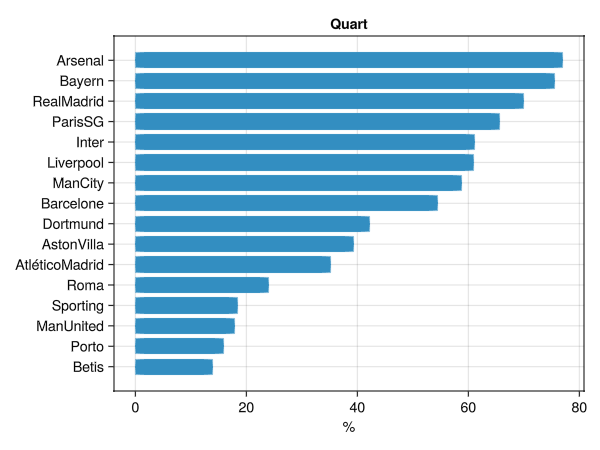

In [7]:
graphique_chances(df; etape = :Quart)

**Comment lire le tableau :**
- `xPoints` : le nombre moyen de points en phase de ligue
- `Top8`, `Top24`, `Elimine` : les chances (en %) de finir dans les 8 premiers, dans les 24 premiers, ou d'être éliminé dès la phase de ligue
- `Huitieme`, `Quart`, `Demie`, `Finale`, `Vainqueur` : les chances (en %) d'arriver à cette étape

*(Si on relance, les chiffres peuvent un peu bouger selon le nombre de threads de Julia.)*

**Ce qu'on remarque :**

- **Il y a 4 favoris :** Arsenal (environ 22 %), le Bayern (environ 17,5 %), le Real Madrid (environ 13 %) et le PSG (environ 10 %). Même le favori gagne moins d'une fois sur 4 : avec les matchs à élimination directe, une mauvaise soirée suffit pour sortir.
- **Bizarrement, c'est le Bayern qui fait le plus de points en phase de ligue, mais c'est Arsenal qui gagne le plus souvent.** On pense que c'est parce qu'Arsenal a le meilleur poids (le championnat anglais a un gros coefficient : $F = 122{,}4$ contre $119{,}9$ pour le Bayern). Le Bayern aurait donc des adversaires plus faciles en phase de ligue. En plus, Arsenal est meilleur aux tirs au but (environ 83 % contre 78 %).
- **Finir dans le top 8 aide beaucoup**, parce qu'on évite le barrage. Les gros clubs y arrivent dans 55 à 80 % des cas.
- **En bas du tableau**, Sabah FC, le LASK et Viking sont éliminés dès la phase de ligue environ 9 fois sur 10.
- Sur le graphique des quarts, les clubs sont plus proches : beaucoup arrivent souvent en quarts. C'est après que les favoris font la différence.

## 6. On compare les 4 modèles

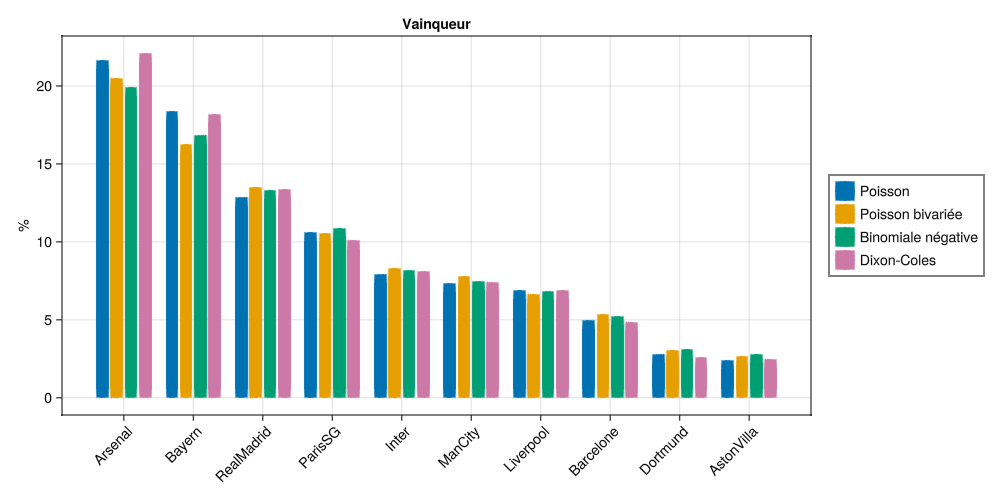

In [8]:
comparaison_modeles(N)

**Ce qu'on remarque :**

- **Les 4 modèles donnent presque le même classement** : Arsenal, Bayern, Real Madrid, PSG, puis Inter, City et Liverpool. Les différences entre modèles sont petites (1 à 3 points au maximum).
- Avec la **binomiale négative**, les favoris gagnent un peu moins souvent (Arsenal environ 19 %). C'est logique : les scores varient plus, donc il y a plus de surprises.
- Avec **Dixon-Coles**, c'est l'inverse, les favoris gagnent un peu plus (Arsenal environ 22 %, Bayern environ 19 %).
- Donc **le choix du modèle ne change pas grand-chose** au résultat final.

## 7. Et si on change le nombre de buts ($\mu$) ?

In [9]:
for μ in [1.0, 1.25, 1.5]
    d = classement_stats(rand(N, ModeleDixonColes(μ = μ); seed = 1))
    println("μ = $μ : ", first(sort(d, :Vainqueur, rev = true), 3)[:, [:Club, :Vainqueur]])
end

μ = 1.0 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         20.2
   2 │ Bayern          17.31
   3 │ RealMadrid      13.65


μ = 1.25 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         22.11
   2 │ Bayern          17.5
   3 │ RealMadrid      13.15


μ = 1.5 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         21.87
   2 │ Bayern          18.77
   3 │ RealMadrid      13.93


**Ce qu'on remarque :**

- Les 3 favoris restent les mêmes quel que soit $\mu$.
- Avec plus de buts, le meilleur club gagne un peu plus souvent, car il y a moins de matchs nuls et donc moins de tirs au but (où tout peut arriver). Par exemple, le Bayern passe d'environ 17,3 % à 18,8 % quand $\mu$ passe de 1 à 1,5.
- Mais l'effet est petit (1 à 2 points), donc ce n'est pas grave si $\mu$ n'est pas réglé parfaitement.

## 8. Est-ce que 10 000 simulations, c'est assez ?

In [10]:
for n in [1000, 10000, 50000]
    d = classement_stats(rand(n, ModeleDixonColes(); seed = 2))
    println("n = $n : ", first(sort(d, :Vainqueur, rev = true), 3)[:, [:Club, :Vainqueur]])
end

n = 1000 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal          20.1
   2 │ Bayern           15.9
   3 │ RealMadrid       15.0


n = 10000 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         21.65
   2 │ Bayern          18.01
   3 │ RealMadrid      13.6

n = 50000 : 3×2 DataFrame
 Row │ Club        Vainqueur 
     │ String      Float64   
─────┼───────────────────────
   1 │ Arsenal         21.46
   2 │ Bayern          18.09
   3 │ RealMadrid      13.42


On a relancé avec 1 000, 10 000 et 50 000 simulations pour comparer.

L'erreur faite en estimant une probabilité $p$ avec $n$ essais est d'environ $\sqrt{p(1-p)/n}$. Pour $p = 0{,}2$ :

| $n$ | erreur |
|---|---|
| 1 000 | environ 1,3 point |
| 10 000 | environ 0,4 point |
| 50 000 | environ 0,2 point |

**Ce qu'on remarque :** on retrouve bien ça. Avec 1 000 simulations, le Bayern est à 15,9 % au lieu d'environ 18 %, ce n'est pas assez précis. Entre 10 000 et 50 000, les chiffres ne bougent presque plus. **10 000 simulations suffisent** : l'erreur (0,4 point) est bien plus petite que les écarts entre les clubs.

## 9. Conclusion

En simulant 10 000 fois la Ligue des champions, on a pu estimer les chances de chaque club à chaque étape. D'après nos simulations (modèle de Dixon-Coles), **Arsenal est le favori avec environ 22 % de chances**, devant le Bayern, le Real Madrid et le PSG.

- Les résultats sont **assez stables** : ils changent peu quand on change de modèle ou de nombre de buts, et 10 000 simulations donnent une bonne précision.
- Même le favori gagne moins d'une fois sur 4 : en Ligue des champions, il y a beaucoup de hasard.

**Les limites de notre projet :**
- la force d'un club ne change pas pendant la compétition (pas de blessures, pas de forme du moment) ;
- le tirage de la phase finale est simplifié ;
- certains paramètres ($\mu$, $\rho$, l'avantage à domicile de 1,2) ont été choisis à la main, on ne les a pas calculés à partir de vrais matchs.